In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
import os

In [24]:
# get present working directory
cwd = os.getcwd()
cwd

'/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/analyse_input_features'

In [25]:
data_dir = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set"

# Load processed (i.e. normalized and transformed) data used for training model
### Only looking at sepsis patients
We load the raw data for comparison purposes below

In [69]:
# load train_dynamic_deephit_dataset.h5 file
train_dynamic_deephit_dataset_file_path = os.path.join(data_dir, "train_dynamic_deephit_dataset.h5")
train_dynamic_deephit_dataset_file = h5.File(train_dynamic_deephit_dataset_file_path, "r")
with h5.File(train_dynamic_deephit_dataset_file_path, "r") as train_dynamic_deephit_dataset_file:
    # List all groups
    print("Keys: %s" % train_dynamic_deephit_dataset_file.keys())
    processed_feature_names = train_dynamic_deephit_dataset_file["feature_names"][:]
    trajectories = train_dynamic_deephit_dataset_file["trajectories"][:]
    index_ptr = train_dynamic_deephit_dataset_file["index_ptr"][:]
    stay_ids = train_dynamic_deephit_dataset_file["stay_ids"][:]
    event = train_dynamic_deephit_dataset_file["event"][:]

Keys: <KeysViewHDF5 ['carry_forward_ind', 'event', 'feature_dim', 'feature_names', 'index_ptr', 'physiological_feature_ind', 'physiological_feature_type', 'response_zero_ind', 'stay_ids', 'time_to_event', 'time_to_event_raw', 'trajectories']>


In [70]:
dynamic_deephit_dir = '/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/final_model'
# find folder inside dynamic_deephit_dir
final_model_dir = [f for f in os.listdir(dynamic_deephit_dir) if os.path.isdir(os.path.join(dynamic_deephit_dir, f))][0]
final_model_dir_path = os.path.join(dynamic_deephit_dir, final_model_dir)

predictions_file_path = os.path.join(final_model_dir_path, "train_set_predictions.h5")
with h5.File(predictions_file_path, "r") as predictions_file:
    # List all groups
    print("Keys: %s" % predictions_file.keys())
    health_score = predictions_file["health_score"][:]
    index_ptr2 = predictions_file["index_ptr"][:]

Keys: <KeysViewHDF5 ['carry_forward_ind', 'compressed_latents', 'entropy', 'event', 'feature_dim', 'feature_names', 'health_score', 'index_ptr', 'model_outputs', 'physiological_feature_ind', 'physiological_feature_type', 'predictions', 'response_zero_ind', 'stay_ids']>


In [71]:
# restrict to sepsis cohort
sepsis_cohort_path = "/home/jake/Documents/AI_Clinician/choc_data/cohorts/sepsis/stay_ids.csv"

# load sepsis cohort stay_ids
sepsis_stay_ids = pd.read_csv(sepsis_cohort_path)
sepsis_stay_ids

,stay_id
0,1163732912
1,1163738773
2,1163740044
3,1163744439
4,1163745160
...,...
5178,1189395190
5179,1189395314
5180,1189418957
5181,1189420203


In [82]:
def restrict_to_sepsis_cohort(
        stay_ids, 
        sepsis_stay_ids, 
        index_ptr, 
        patient_level_data=None,
        patient_level_data_name=None,
        continuous_data = None, 
        continuous_data_name=None):
    # Create boolean mask for stays to keep
    mask = np.isin(stay_ids, sepsis_stay_ids)
    indices_to_keep = np.where(mask)[0]

    if patient_level_data is not None:
        if patient_level_data.shape[0] != stay_ids.shape[0]:
            print("Inconsistent patient-level data shape, aborting filtering")
            print(f"Shape of unfiltered {patient_level_data_name}: {patient_level_data.shape}")
        else:
            print("Patient-level data shape is consistent, proceeding with filtering")
            restricted_patient_level_data = patient_level_data[mask]
            print(f"Shape of {patient_level_data_name} after filtering for sepsis cohort: {restricted_patient_level_data.shape}")
    else:
        restricted_patient_level_data = None

    if continuous_data is not None:
        if index_ptr[-1] != continuous_data.shape[0]:
            print("Inconsistent indexing detected, aborting filtering")
            print(f"Shape of unfiltered {continuous_data_name}: {continuous_data.shape}")
        else:
            print("Indexing is consistent, proceeding with filtering")
            traj_mask = np.zeros(continuous_data.shape[0], dtype=bool)
            for idx in indices_to_keep:
                start_idx = index_ptr[idx]
                end_idx = index_ptr[idx + 1]
                traj_mask[start_idx:end_idx] = True

            restricted_continuous_data = continuous_data[traj_mask]
            print(f"Shape of {continuous_data_name} after filtering for sepsis cohort: {restricted_continuous_data.shape}")
    else:
        restricted_continuous_data = None

    # restrict index_ptr and stay_ids to sepsis cohort
    restricted_sepsis_stay_ids = stay_ids[mask]
    print(f"Number of stays in sepsis cohort: {len(restricted_sepsis_stay_ids)}")

    # Rebuild index_ptr
    restricted_index_ptr = np.zeros(len(indices_to_keep) + 1, dtype=np.int32)
    for i, idx in enumerate(indices_to_keep):
        start_idx = index_ptr[idx]
        end_idx = index_ptr[idx + 1]
        restricted_index_ptr[i + 1] = restricted_index_ptr[i] + (end_idx - start_idx)

    if continuous_data is not None:
        print(f"Final index_ptr value: {restricted_index_ptr[-1]}, should match length of restricted continuous data: {restricted_continuous_data.shape[0]}")

    return restricted_sepsis_stay_ids, restricted_index_ptr, restricted_patient_level_data, restricted_continuous_data 


In [83]:
restricted_stay_ids, restricted_index_ptr, _, restricted_health_score = restrict_to_sepsis_cohort(
    stay_ids, 
    np.array(sepsis_stay_ids["stay_id"]), 
    index_ptr2, 
    continuous_data = health_score, 
    continuous_data_name='health_score'
)
_, _, _, restricted_trajectories = restrict_to_sepsis_cohort(
    stay_ids, 
    np.array(sepsis_stay_ids["stay_id"]), 
    index_ptr, 
    continuous_data = trajectories, 
    continuous_data_name='trajectories'
)

_, _, restricted_event, _ = restrict_to_sepsis_cohort(
    stay_ids, 
    np.array(sepsis_stay_ids["stay_id"]), 
    index_ptr,
    patient_level_data = event,
    patient_level_data_name='event'
)   

Indexing is consistent, proceeding with filtering
Shape of health_score after filtering for sepsis cohort: (715424,)
Number of stays in sepsis cohort: 1488
Final index_ptr value: 715424, should match length of restricted continuous data: 715424
Indexing is consistent, proceeding with filtering
Shape of trajectories after filtering for sepsis cohort: (715424, 155)
Number of stays in sepsis cohort: 1488
Final index_ptr value: 715424, should match length of restricted continuous data: 715424
Patient-level data shape is consistent, proceeding with filtering
Shape of event after filtering for sepsis cohort: (1488,)
Number of stays in sepsis cohort: 1488


# Raw data
### restrict to same patients

In [31]:
# load train.h5 file
train_file_path = os.path.join(data_dir, "train.h5")
train_file = h5.File(train_file_path, "r")
with h5.File(train_file_path, "r") as train_file:
    # List all groups
    print("Keys: %s" % train_file.keys())
    # load feature_names, index_ptr, stay_ids and trajectories
    feature_names = train_file["feature_names"][:]
    index_ptr = train_file["index_ptr"][:]
    stay_ids = train_file["stay_ids"][:]
    trajectories = train_file["trajectories"][:]

Keys: <KeysViewHDF5 ['feature_names', 'index_ptr', 'stay_ids', 'trajectories']>


In [32]:
# print features names, stored as bytes, so decode to string
feature_names = [name.decode("utf-8") for name in feature_names]
for name in feature_names:
    print(name)

n_features = len(feature_names)
print(f"Number of features: {n_features}")

print("trajectories.shape):", trajectories.shape)

# find intake feature index
intake_feature_index = feature_names.index("intake")
print(f"Index of 'intake' feature: {intake_feature_index}")

# find vis feature index
vis_feature_index = feature_names.index("vis")
print(f"Index of 'vis' feature: {vis_feature_index}")

airway_type
airway_type_mask
airway_type_delta
breath_sequence
breath_sequence_mask
breath_sequence_delta
control_variable
control_variable_mask
control_variable_delta
expiratory_pressure
expiratory_pressure_mask
expiratory_pressure_delta
fio2
fio2_mask
fio2_delta
inspiratory_time
inspiratory_time_mask
inspiratory_time_delta
mean_airway_pressure
mean_airway_pressure_mask
mean_airway_pressure_delta
mode_of_ventilation
mode_of_ventilation_mask
mode_of_ventilation_delta
nitric_oxide
nitric_oxide_mask
nitric_oxide_delta
oxygen_flow
oxygen_flow_mask
oxygen_flow_delta
peep
peep_mask
peep_delta
pip
pip_mask
pip_delta
weight_kg
ecls_support_type
on_ecls
furosemide
hydralazine
labetalol
nitroglycerin
nitroprusside
intake
output
alt
alt_mask
alt_delta
calcium
calcium_mask
calcium_delta
chloride
chloride_mask
chloride_delta
creatinine
creatinine_mask
creatinine_delta
crp
crp_mask
crp_delta
hematocrit
hematocrit_mask
hematocrit_delta
hemoglobin
hemoglobin_mask
hemoglobin_delta
neutrophil_count
neu

In [33]:
raw_restricted_stay_ids, raw_restricted_index_ptr, raw_restricted_trajectories = restrict_to_sepsis_cohort(stay_ids, restricted_stay_ids, index_ptr, trajectories, continuous_data_name='trajectories')

Indexing is consistent, proceeding with filtering
Shape of trajectories after filtering for sepsis cohort: (715424, 155)
Number of stays in sepsis cohort: 1488
Final index_ptr value: 715424, should match length of restricted continuous data: 715424


In [34]:
# contfirm that the restricted_stay_ids and raw_restricted_stay_ids are the same
if np.array_equal(restricted_stay_ids, raw_restricted_stay_ids):
    print("restricted_stay_ids and raw_restricted_stay_ids are the same")

# confirm that the restricted_index_ptr and raw_restricted_index_ptr are the same
if np.array_equal(restricted_index_ptr, raw_restricted_index_ptr):
    print("restricted_index_ptr and raw_restricted_index_ptr are the same")

restricted_stay_ids and raw_restricted_stay_ids are the same
restricted_index_ptr and raw_restricted_index_ptr are the same


# Raw fluids

In [35]:
intake = raw_restricted_trajectories[:, intake_feature_index]

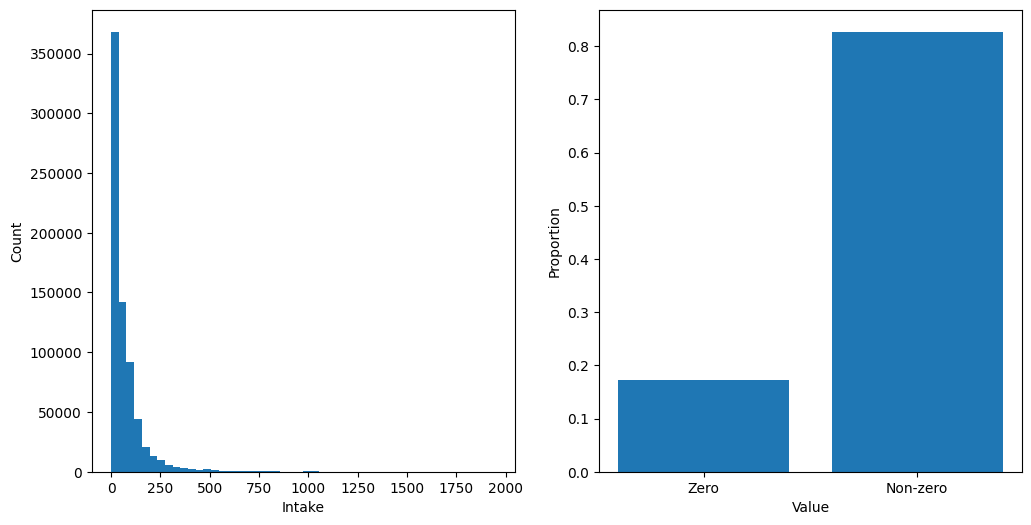

In [36]:
# plot full distribution of intake values is subplot on left
plt.subplot(1, 2, 1)
plt.hist(intake, bins=50)
plt.xlabel("Intake")
plt.ylabel("Count")

# plot a histogram of number of zero and non-zero values is two bars on the right subplot
total_count = len(intake)
n_zeros = np.sum(intake == 0)
n_non_zeros = np.sum(intake != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count

plt.subplot(1, 2, 2)
plt.bar(["Zero", "Non-zero"], [proportion_zeros, proportion_non_zeros])
plt.ylabel("Proportion") 
plt.xlabel("Value")

# make the figure wider
plt.gcf().set_size_inches(12, 6)

Text(0.5, 1.0, 'Distribution of non-zero intake values')

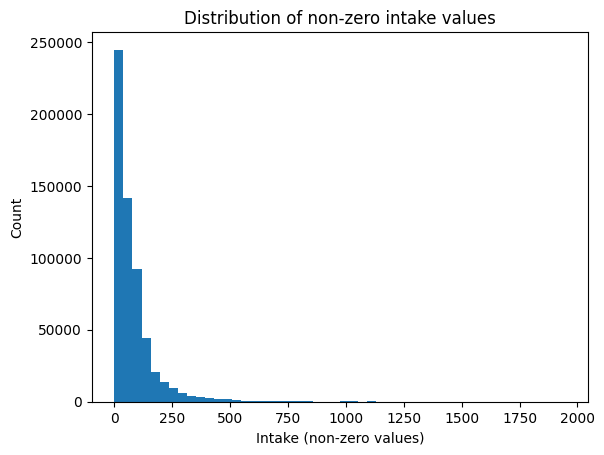

In [37]:

# plot the distribution of intake values for non-zero values only
non_zero_intake = intake[intake != 0]
plt.figure()
plt.hist(non_zero_intake, bins=50)
plt.xlabel("Intake (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero intake values")


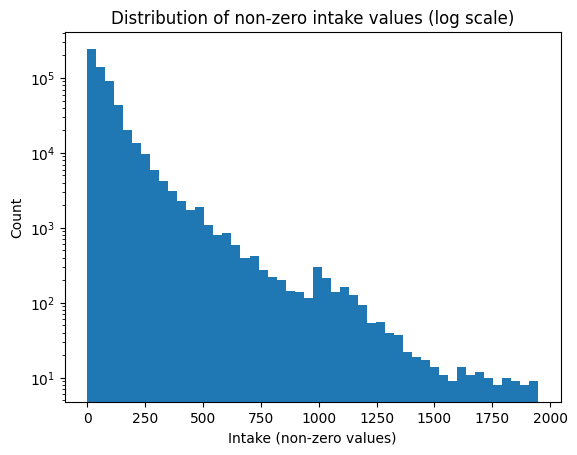

In [38]:
# plot the distribution of intake values for non-zero values only on log scale
plt.figure()
plt.hist(non_zero_intake, bins=50)
plt.xlabel("Intake (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero intake values (log scale)")
plt.yscale("log")

In [39]:
# print mean, median, std, min, max of intake values for non-zero values only
mean_intake = np.mean(non_zero_intake)
median_intake = np.median(non_zero_intake)
std_intake = np.std(non_zero_intake)
min_intake = np.min(non_zero_intake)
max_intake = np.max(non_zero_intake)
print(f"Mean of non-zero intake values: {mean_intake}")
print(f"Median of non-zero intake values: {median_intake}")
print(f"Standard deviation of non-zero intake values: {std_intake}")
print(f"Minimum of non-zero intake values: {min_intake}")   
print(f"Maximum of non-zero intake values: {max_intake}")   

Mean of non-zero intake values: 79.95555114746094
Median of non-zero intake values: 50.25
Standard deviation of non-zero intake values: 109.23355865478516
Minimum of non-zero intake values: 0.0010000000474974513
Maximum of non-zero intake values: 1948.0400390625


## Processed fluids

In [43]:
# get intake and vis feature indices from feature_names array
feature_names_str = np.asarray(processed_feature_names).astype(str)

intake_matches = np.where(feature_names_str == "intake")[0]
vis_matches = np.where(feature_names_str == "vis")[0]
intake_feature_index = int(intake_matches[0])
vis_feature_index = int(vis_matches[0])

In [44]:
# get features from trajectories
intake = restricted_trajectories[:, intake_feature_index]
vis = restricted_trajectories[:, vis_feature_index]

In [45]:
# print n_rows
print(f"Number of rows: {len(intake)}")

Number of rows: 715424


In [46]:
# get mean, median, std, min, max of intake and vis features
mean_intake = np.mean(intake)
median_intake = np.median(intake)
std_intake = np.std(intake)
min_intake = np.min(intake)
max_intake = np.max(intake)

print(f"Mean of intake values: {mean_intake}")
print(f"Median of intake values: {median_intake}")
print(f"Standard deviation of intake values: {std_intake}")
print(f"Minimum of intake values: {min_intake}")
print(f"Maximum of intake values: {max_intake}")

Mean of intake values: 0.40887734293937683
Median of intake values: 0.47668302059173584
Standard deviation of intake values: 0.23940719664096832
Minimum of intake values: 0.0
Maximum of intake values: 1.0


In [47]:
# get mean, median, std, min, max of non-zero intake values
non_zero_intake = intake[intake != 0]
mean_non_zero_intake = np.mean(non_zero_intake)
median_non_zero_intake = np.median(non_zero_intake)
std_non_zero_intake = np.std(non_zero_intake)
min_non_zero_intake = np.min(non_zero_intake)   
max_non_zero_intake = np.max(non_zero_intake)
print(f"Mean of non-zero intake values: {mean_non_zero_intake}")
print(f"Median of non-zero intake values: {median_non_zero_intake}")
print(f"Standard deviation of non-zero intake values: {std_non_zero_intake}")
print(f"Minimum of non-zero intake values: {min_non_zero_intake}")
print(f"Maximum of non-zero intake values: {max_non_zero_intake}")

Mean of non-zero intake values: 0.4943188428878784
Median of non-zero intake values: 0.5196921229362488
Standard deviation of non-zero intake values: 0.16449160873889923
Minimum of non-zero intake values: 0.0001319456350756809
Maximum of non-zero intake values: 1.0


Proportion of zero intake values: 0.17284715078051616
Proportion of non-zero intake values: 0.8271528492194838


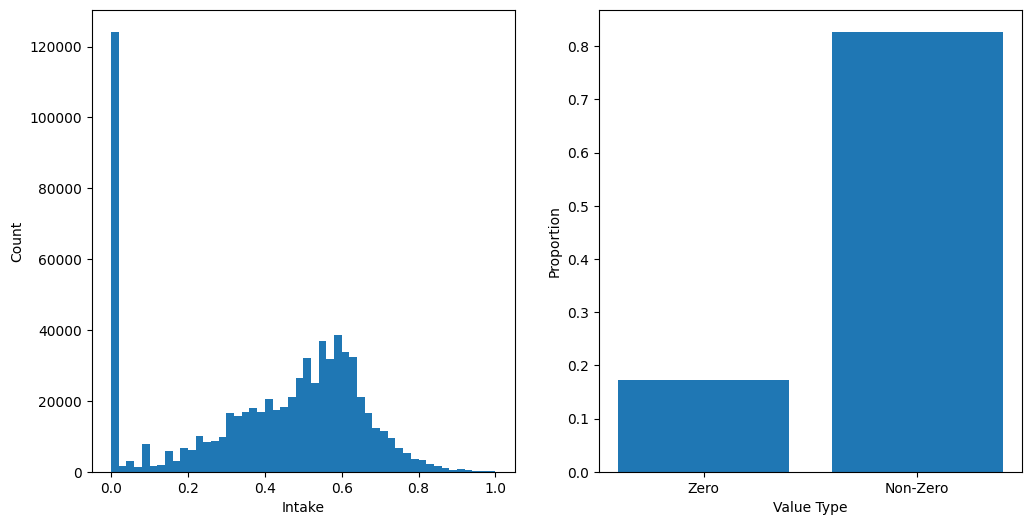

In [48]:
# plot distribution of intake values on left subplot, and proportion of zero and non-zero values on right subplot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(intake, bins=50)
plt.xlabel("Intake")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
total_count = len(intake)
n_zeros = np.sum(intake == 0)
n_non_zeros = np.sum(intake != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count
plt.bar([0, 1], [proportion_zeros, proportion_non_zeros], tick_label=["Zero", "Non-Zero"])
plt.xlabel("Value Type")
plt.ylabel("Proportion")   

print(f"Proportion of zero intake values: {proportion_zeros}")
print(f"Proportion of non-zero intake values: {proportion_non_zeros}")

## VIS

In [49]:
# get mean, median, std, min, max of vis feature
mean_vis = np.mean(vis)
median_vis = np.median(vis)
std_vis = np.std(vis)   
min_vis = np.min(vis)
max_vis = np.max(vis)

print(f"Mean of vis values: {mean_vis}")
print(f"Median of vis values: {median_vis}")
print(f"Standard deviation of vis values: {std_vis}")
print(f"Minimum of vis values: {min_vis}")
print(f"Maximum of vis values: {max_vis}")

Mean of vis values: 0.02021082490682602
Median of vis values: 0.0
Standard deviation of vis values: 0.0763692855834961
Minimum of vis values: 0.0
Maximum of vis values: 1.0


In [50]:
# get mean, median, std, min, max of non-zero vis values
non_zero_vis = vis[vis != 0]
mean_non_zero_vis = np.mean(non_zero_vis)
median_non_zero_vis = np.median(non_zero_vis)
std_non_zero_vis = np.std(non_zero_vis)
min_non_zero_vis = np.min(non_zero_vis)
max_non_zero_vis = np.max(non_zero_vis)
print(f"Mean of non-zero vis values: {mean_non_zero_vis}")
print(f"Median of non-zero vis values: {median_non_zero_vis}")
print(f"Standard deviation of non-zero vis values: {std_non_zero_vis}")
print(f"Minimum of non-zero vis values: {min_non_zero_vis}")
print(f"Maximum of non-zero vis values: {max_non_zero_vis}")

Mean of non-zero vis values: 0.26203885674476624
Median of non-zero vis values: 0.22199366986751556
Standard deviation of non-zero vis values: 0.11067347973585129
Minimum of non-zero vis values: 0.006044956389814615
Maximum of non-zero vis values: 1.0


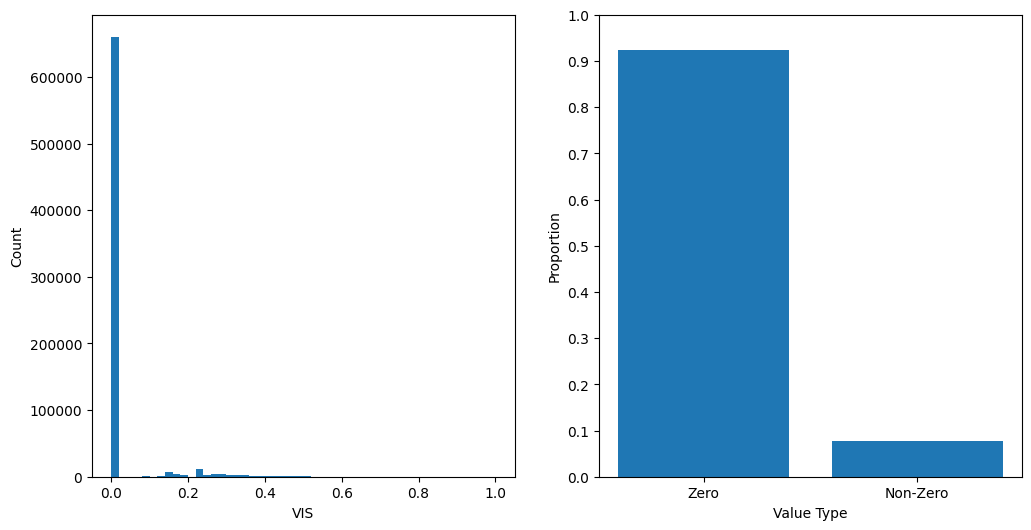

Proportion of zero doses for vis: 0.9228709129131816
Proportion of non-zero doses for vis: 0.07712908708681844


In [51]:
# plot distribution of vis values on left subplot, and proportion of zero and non-zero values on right subplot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(vis, bins=50)
plt.xlabel("VIS")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
total_count = len(vis)
n_zeros = np.sum(vis == 0)
n_non_zeros = np.sum(vis != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count
plt.bar([0, 1], [proportion_zeros, proportion_non_zeros], tick_label=["Zero", "Non-Zero"])
plt.xlabel("Value Type")
plt.ylabel("Proportion")
# place y-ticks every 0.1
plt.yticks(np.arange(0, 1.1, 0.1))
plt.show()

print(f"Proportion of zero doses for vis: {proportion_zeros}")
print(f"Proportion of non-zero doses for vis: {proportion_non_zeros}")

Text(0.5, 1.0, 'Distribution of non-zero VIS values')

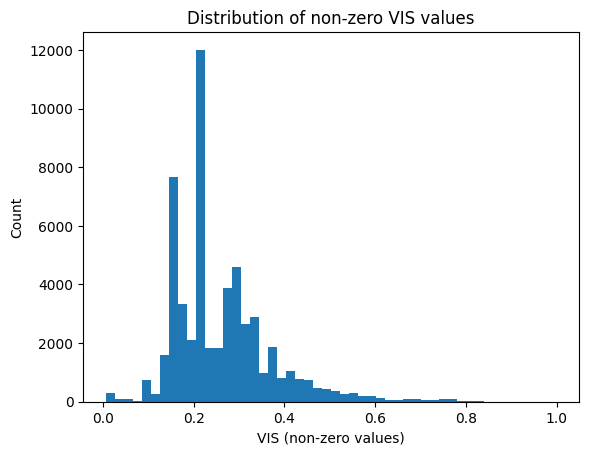

In [52]:
# plot just non-zero vis values as histogram
plt.figure()
plt.hist(non_zero_vis, bins=50)
plt.xlabel("VIS (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero VIS values")


# intake and vis

In [53]:
# get the rate of zero values for both simultaneously and plot as a bar chart
n_both_zero = np.sum((intake == 0) & (vis == 0))
n_intake_zero_vis_non_zero = np.sum((intake == 0) & (vis != 0))
n_intake_non_zero_vis_zero = np.sum((intake != 0) & (vis == 0))
n_intake_non_zero_vis_non_zero = np.sum((intake != 0) & (vis != 0))

total_count = len(intake)
proportion_both_zero = n_both_zero / total_count
proportion_intake_zero_vis_non_zero = n_intake_zero_vis_non_zero / total_count
proportion_intake_non_zero_vis_zero = n_intake_non_zero_vis_zero / total_count
proportion_intake_non_zero_vis_non_zero = n_intake_non_zero_vis_non_zero / total_count

print(f"Proportion of both intake and vis zero: {proportion_both_zero}")
print(f"Proportion of intake zero and vis non-zero: {proportion_intake_zero_vis_non_zero}")
print(f"Proportion of intake non-zero and vis zero: {proportion_intake_non_zero_vis_zero}")
print(f"Proportion of both intake and vis non-zero: {proportion_intake_non_zero_vis_non_zero}")


Proportion of both intake and vis zero: 0.17264028044907634
Proportion of intake zero and vis non-zero: 0.00020687033143981752
Proportion of intake non-zero and vis zero: 0.7502306324641052
Proportion of both intake and vis non-zero: 0.07692221675537862


# Health score

In [54]:
# print health score mean, median, std, min, max
mean_health_score = np.mean(health_score)
median_health_score = np.median(health_score)
std_health_score = np.std(health_score)
min_health_score = np.min(health_score)
max_health_score = np.max(health_score)
print(f"Mean of health score values: {mean_health_score}")
print(f"Median of health score values: {median_health_score}")
print(f"Standard deviation of health score values: {std_health_score}")
print(f"Minimum of health score values: {min_health_score}")
print(f"Maximum of health score values: {max_health_score}")

Mean of health score values: 80.81243133544922
Median of health score values: 84.34191131591797
Standard deviation of health score values: 13.354902267456055
Minimum of health score values: 5.378633499145508
Maximum of health score values: 99.14541625976562


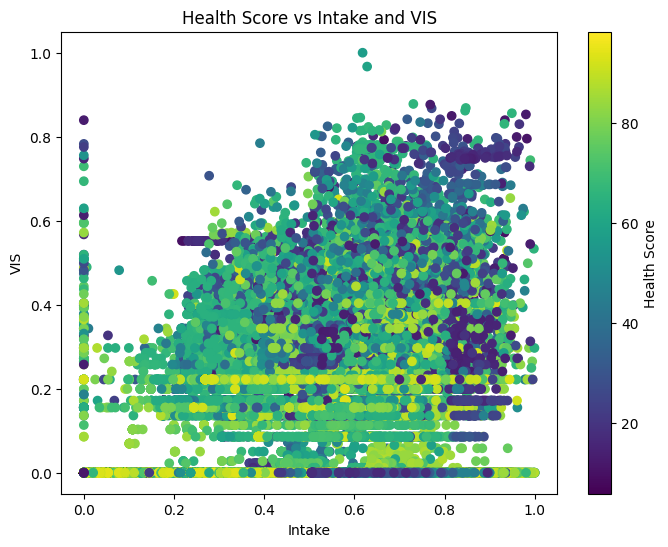

In [59]:
# plot a linear regression of health score vs intake and vis values, with intake on x-axis 
# and vis on y-axis, and health score as color
plt.figure(figsize=(8, 6))
plt.scatter(intake, vis, c=restricted_health_score, cmap='viridis')
plt.xlabel('Intake')
plt.ylabel('VIS')
plt.title('Health Score vs Intake and VIS')
plt.colorbar(label='Health Score')
plt.show()

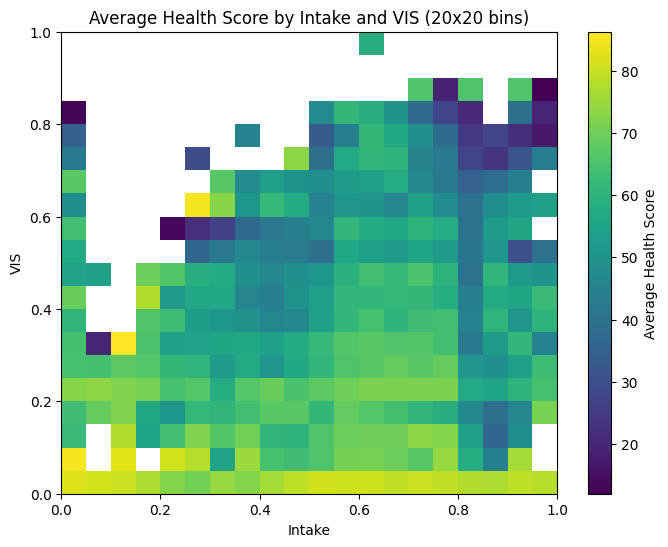

In [61]:
# plot average health score as a 20x20 heatmap over intake (x) and vis (y),
# with unoccupied bins shown in white instead of the colormap
n_bins = 20

joint_counts, fluid_edges, vaso_edges = np.histogram2d(intake, vis, bins=n_bins)
health_sums, _, _ = np.histogram2d(intake, vis, bins=[fluid_edges, vaso_edges], weights=restricted_health_score)

with np.errstate(invalid="ignore", divide="ignore"):
    avg_health = health_sums / joint_counts
avg_health = np.ma.masked_where(joint_counts == 0, avg_health)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="white")

plt.figure(figsize=(8, 6))
im = plt.pcolormesh(fluid_edges, vaso_edges, avg_health.T, cmap=cmap, shading="auto")
plt.xlabel("Intake")
plt.ylabel("VIS")
plt.title("Average Health Score by Intake and VIS (20x20 bins)")
plt.colorbar(im, label="Average Health Score")
plt.show()

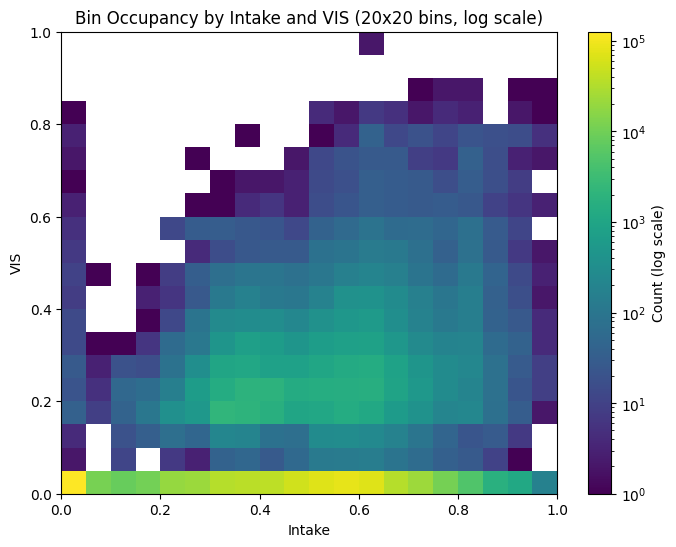

In [62]:
# plot the same 20x20 heatmap, but heat is bin occupancy (count) instead of average health score,
# with unoccupied bins shown in white instead of the colormap, and counts on a log scale
from matplotlib.colors import LogNorm

counts_masked = np.ma.masked_where(joint_counts == 0, joint_counts)

cmap_counts = plt.get_cmap("viridis").copy()
cmap_counts.set_bad(color="white")

plt.figure(figsize=(8, 6))
im = plt.pcolormesh(
    fluid_edges, vaso_edges, counts_masked.T, cmap=cmap_counts,
    norm=LogNorm(vmin=1, vmax=counts_masked.max()), shading="auto",
)
plt.xlabel("Intake")
plt.ylabel("VIS")
plt.title("Bin Occupancy by Intake and VIS (20x20 bins, log scale)")
plt.colorbar(im, label="Count (log scale)")
plt.show()

In [63]:
def build_zero_occupancy_action_pool(fluid_bin_edges, vaso_bin_edges, joint_counts, min_count=1):
    """
    Identifies action-space bins with near-zero occupancy in the dataset,
    and returns their bounds so we can sample actions uniformly within
    each unsupported bin. joint_counts: (n_fluid_bins, n_vaso_bins) array.
    """
    zero_bins = []
    for i in range(joint_counts.shape[0]):
        for j in range(joint_counts.shape[1]):
            if joint_counts[i, j] < min_count:
                zero_bins.append((
                    fluid_bin_edges[i], fluid_bin_edges[i + 1],
                    vaso_bin_edges[j], vaso_bin_edges[j + 1],
                ))
    return zero_bins  # list of (f_lo, f_hi, v_lo, v_hi)

In [64]:
# once, at trainer init or setup
zero_bins = build_zero_occupancy_action_pool(fluid_edges, vaso_edges, joint_counts, min_count=1)
zero_bins

[(0.0, 0.05, 0.8500000000000001, 0.9),
 (0.0, 0.05, 0.9, 0.9500000000000001),
 (0.0, 0.05, 0.9500000000000001, 1.0),
 (0.05, 0.1, 0.05, 0.1),
 (0.05, 0.1, 0.1, 0.15000000000000002),
 (0.05, 0.1, 0.35000000000000003, 0.4),
 (0.05, 0.1, 0.4, 0.45),
 (0.05, 0.1, 0.5, 0.55),
 (0.05, 0.1, 0.55, 0.6000000000000001),
 (0.05, 0.1, 0.6000000000000001, 0.65),
 (0.05, 0.1, 0.65, 0.7000000000000001),
 (0.05, 0.1, 0.7000000000000001, 0.75),
 (0.05, 0.1, 0.75, 0.8),
 (0.05, 0.1, 0.8, 0.8500000000000001),
 (0.05, 0.1, 0.8500000000000001, 0.9),
 (0.05, 0.1, 0.9, 0.9500000000000001),
 (0.05, 0.1, 0.9500000000000001, 1.0),
 (0.1, 0.15000000000000002, 0.35000000000000003, 0.4),
 (0.1, 0.15000000000000002, 0.4, 0.45),
 (0.1, 0.15000000000000002, 0.45, 0.5),
 (0.1, 0.15000000000000002, 0.5, 0.55),
 (0.1, 0.15000000000000002, 0.55, 0.6000000000000001),
 (0.1, 0.15000000000000002, 0.6000000000000001, 0.65),
 (0.1, 0.15000000000000002, 0.65, 0.7000000000000001),
 (0.1, 0.15000000000000002, 0.7000000000000001,

# average fluid and vaso doses as a function of remaining steps 
### this is to understand terminal only RL results where vaso doses collapse to zero

In [95]:
# convert restricted_index_prt to steps_to_go
steps_to_go = np.zeros(restricted_index_ptr[-1], dtype=int)
mortality_all_steps = np.zeros(restricted_index_ptr[-1], dtype=int)
for i in range(len(restricted_index_ptr) - 1):
    start_idx = restricted_index_ptr[i]
    end_idx = restricted_index_ptr[i + 1]
    event_value = restricted_event[i]
    mortality_all_steps[start_idx:end_idx] = event_value
    steps_to_go[start_idx:end_idx] = np.arange(end_idx - start_idx, 0, -1)

In [100]:
restricted_event

array([0, 1, 0, ..., 0, 0, 1], dtype=int32)

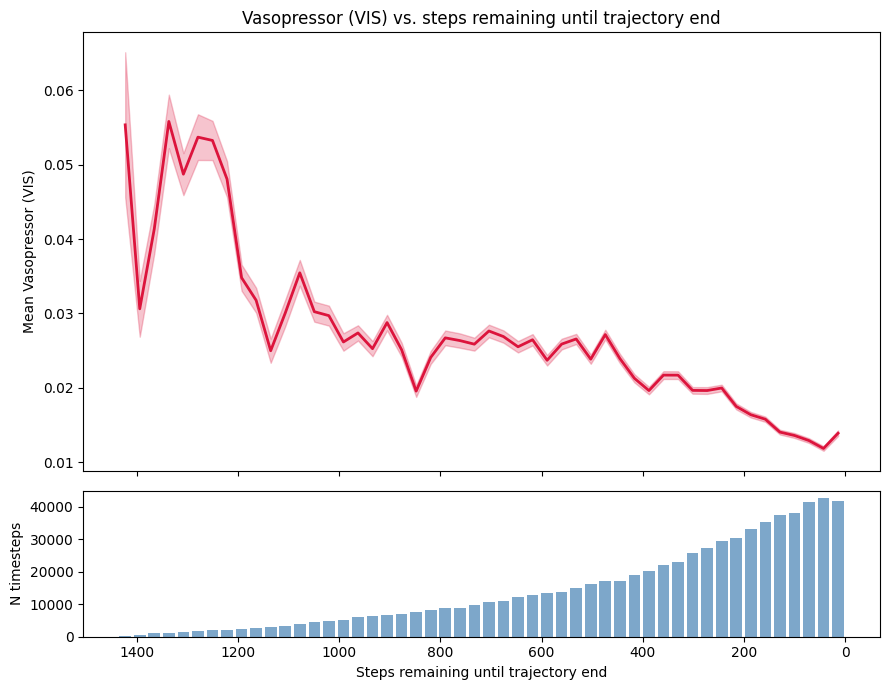

In [101]:
import numpy as np
import matplotlib.pyplot as plt

def plot_dose_by_steps_remaining(dose, steps_to_go, dose_name="VIS", max_steps=None, n_bins=50, log_x=False):
    """
    Plots mean dose as a function of steps remaining until trajectory end,
    with a shaded standard-error band. Designed to check whether dose
    (e.g. vasopressor) systematically declines as patients approach
    discharge/trajectory end — the survivorship-confound check.

    dose : array of per-timestep dose values (e.g. vis)
    steps_to_go : array, same length, steps remaining to end of trajectory
    max_steps : optionally truncate the x-axis (long tails get sparse/noisy)
    n_bins : number of bins to group steps_to_go into (use bins rather than
             raw integer steps, since counts get sparse at large steps_to_go)
    log_x : set True if steps_to_go spans a wide range and you want to see
            behavior across scales more clearly (e.g. days vs hours)
    """
    dose = np.asarray(dose)
    steps_to_go = np.asarray(steps_to_go)

    if max_steps is not None:
        mask = steps_to_go <= max_steps
        dose = dose[mask]
        steps_to_go = steps_to_go[mask]

    if log_x:
        # avoid log(0) — steps_to_go=0 is the terminal step itself
        bin_edges = np.logspace(0, np.log10(steps_to_go.max() + 1), n_bins)
        bin_edges = np.concatenate(([0], bin_edges))
    else:
        bin_edges = np.linspace(0, steps_to_go.max(), n_bins + 1)

    bin_idx = np.digitize(steps_to_go, bin_edges) - 1
    bin_idx = np.clip(bin_idx, 0, len(bin_edges) - 2)

    bin_centers = []
    bin_means = []
    bin_sems = []
    bin_counts = []

    for b in range(len(bin_edges) - 1):
        in_bin = bin_idx == b
        n = in_bin.sum()
        if n == 0:
            continue
        vals = dose[in_bin]
        bin_centers.append((bin_edges[b] + bin_edges[b + 1]) / 2)
        bin_means.append(vals.mean())
        bin_sems.append(vals.std() / np.sqrt(n))
        bin_counts.append(n)

    bin_centers = np.array(bin_centers)
    bin_means = np.array(bin_means)
    bin_sems = np.array(bin_sems)
    bin_counts = np.array(bin_counts)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                                     gridspec_kw={'height_ratios': [3, 1]})

    ax1.plot(bin_centers, bin_means, color='crimson', lw=2)
    ax1.fill_between(bin_centers, bin_means - bin_sems, bin_means + bin_sems,
                       color='crimson', alpha=0.25)
    ax1.set_ylabel(f"Mean {dose_name}")
    ax1.set_title(f"{dose_name} vs. steps remaining until trajectory end")
    ax1.invert_xaxis()  # steps_to_go=0 (trajectory end) on the RIGHT, intuitive reading direction
    if log_x:
        ax1.set_xscale('log')

    # sample count subplot — important context, since large steps_to_go bins
    # will have far fewer trajectories long enough to reach them
    ax2.bar(bin_centers, bin_counts, width=(bin_edges[1] - bin_edges[0]) * 0.8,
            color='steelblue', alpha=0.7)
    ax2.set_ylabel("N timesteps")
    ax2.set_xlabel("Steps remaining until trajectory end")
    if log_x:
        ax2.set_yscale('log')

    plt.tight_layout()
    plt.show()

    return {
        "bin_centers": bin_centers,
        "bin_means": bin_means,
        "bin_sems": bin_sems,
        "bin_counts": bin_counts,
    }


# usage
results = plot_dose_by_steps_remaining(vis, steps_to_go, dose_name="Vasopressor (VIS)")

In [106]:
def _bin_dose_by_steps(dose, steps_to_go, max_steps=None, n_bins=50, log_x=False):
    """Helper: bins dose by steps_to_go and returns bin centers/means/sems/counts."""
    dose = np.asarray(dose)
    steps_to_go = np.asarray(steps_to_go)

    if max_steps is not None:
        mask = steps_to_go <= max_steps
        dose = dose[mask]
        steps_to_go = steps_to_go[mask]

    if len(steps_to_go) == 0:
        return np.array([]), np.array([]), np.array([]), np.array([])

    if log_x:
        bin_edges = np.logspace(0, np.log10(steps_to_go.max() + 1), n_bins)
        bin_edges = np.concatenate(([0], bin_edges))
    else:
        bin_edges = np.linspace(0, steps_to_go.max(), n_bins + 1)

    bin_idx = np.digitize(steps_to_go, bin_edges) - 1
    bin_idx = np.clip(bin_idx, 0, len(bin_edges) - 2)

    bin_centers, bin_means, bin_sems, bin_counts = [], [], [], []

    for b in range(len(bin_edges) - 1):
        in_bin = bin_idx == b
        n = in_bin.sum()
        if n == 0:
            continue
        vals = dose[in_bin]
        bin_centers.append((bin_edges[b] + bin_edges[b + 1]) / 2)
        bin_means.append(vals.mean())
        bin_sems.append(vals.std() / np.sqrt(n))
        bin_counts.append(n)

    return (np.array(bin_centers), np.array(bin_means),
            np.array(bin_sems), np.array(bin_counts))


def plot_dose_by_steps_remaining(
        dose,
        steps_to_go,
        mortality_all_steps,
        dose_name="VIS",
        max_steps=None,
        n_steps_to_go=None,
        n_bins=50,
        log_x=False
    ):
    """
    Four-panel plot: survival (left column) vs. mortality (right column),
    each with a dose-vs-steps-remaining curve on top and a sample-count
    bar chart below.

    n_steps_to_go : if set, restricts the data to timesteps with
        steps_to_go <= n_steps_to_go BEFORE binning — use this to zoom in
        on higher temporal resolution right at the trajectory boundary
        (e.g. n_steps_to_go=10 gives you finer-grained bins covering only
        the last 10 steps, rather than n_bins spread across the full range).
        If None, uses all available data (previous behavior).
        This is independent of max_steps, which only controls the x-axis
        plotting range — n_steps_to_go actually restricts which timesteps
        get binned at all, so with the same n_bins you get much finer
        resolution near steps_to_go=0.
    """
    dose = np.asarray(dose)
    steps_to_go = np.asarray(steps_to_go)
    mortality_all_steps = np.asarray(mortality_all_steps)

    if n_steps_to_go is not None:
        zoom_mask = steps_to_go <= n_steps_to_go
        dose = dose[zoom_mask]
        steps_to_go = steps_to_go[zoom_mask]
        mortality_all_steps = mortality_all_steps[zoom_mask]

    survival_mask = mortality_all_steps == 0
    mortality_mask = mortality_all_steps == 1

    surv_centers, surv_means, surv_sems, surv_counts = _bin_dose_by_steps(
        dose[survival_mask], steps_to_go[survival_mask], max_steps, n_bins, log_x
    )
    mort_centers, mort_means, mort_sems, mort_counts = _bin_dose_by_steps(
        dose[mortality_mask], steps_to_go[mortality_mask], max_steps, n_bins, log_x
    )

    fig, axes = plt.subplots(
        2, 2, figsize=(14, 7), sharex='col',
        gridspec_kw={'height_ratios': [3, 1]}
    )
    (ax_surv_dose, ax_mort_dose), (ax_surv_n, ax_mort_n) = axes

    # --- survival column ---
    ax_surv_dose.plot(surv_centers, surv_means, color='seagreen', lw=2)
    ax_surv_dose.fill_between(surv_centers, surv_means - surv_sems, surv_means + surv_sems,
                                color='seagreen', alpha=0.25)
    ax_surv_dose.set_ylabel(f"Mean {dose_name}")
    ax_surv_dose.set_title("Survival trajectories")

    ax_surv_n.bar(surv_centers, surv_counts,
                  width=(surv_centers[1] - surv_centers[0]) * 0.8 if len(surv_centers) > 1 else 1,
                  color='seagreen', alpha=0.6)
    ax_surv_n.set_ylabel("N timesteps")
    ax_surv_n.set_xlabel("Steps remaining until trajectory end")
    ax_surv_dose.invert_xaxis()

    # --- mortality column ---
    ax_mort_dose.plot(mort_centers, mort_means, color='crimson', lw=2)
    ax_mort_dose.fill_between(mort_centers, mort_means - mort_sems, mort_means + mort_sems,
                                color='crimson', alpha=0.25)
    ax_mort_dose.set_title("Mortality trajectories")

    ax_mort_n.bar(mort_centers, mort_counts,
                  width=(mort_centers[1] - mort_centers[0]) * 0.8 if len(mort_centers) > 1 else 1,
                  color='crimson', alpha=0.6)
    ax_mort_n.set_xlabel("Steps remaining until trajectory end")
    ax_mort_dose.invert_xaxis()

    if log_x:
        ax_surv_dose.set_xscale('log')
        ax_surv_n.set_xscale('log')
        ax_mort_dose.set_xscale('log')
        ax_mort_n.set_xscale('log')
        ax_surv_n.set_yscale('log')
        ax_mort_n.set_yscale('log')

    dose_ylim_lo = min(np.nanmin(surv_means - surv_sems) if len(surv_means) else 0,
                        np.nanmin(mort_means - mort_sems) if len(mort_means) else 0)
    dose_ylim_hi = max(np.nanmax(surv_means + surv_sems) if len(surv_means) else 1,
                        np.nanmax(mort_means + mort_sems) if len(mort_means) else 1)
    ax_surv_dose.set_ylim(dose_ylim_lo, dose_ylim_hi)
    ax_mort_dose.set_ylim(dose_ylim_lo, dose_ylim_hi)

    zoom_str = f" (last {n_steps_to_go} steps)" if n_steps_to_go is not None else ""
    fig.suptitle(f"{dose_name} vs. steps remaining, by trajectory outcome{zoom_str}")
    plt.tight_layout()
    plt.show()

    return {
        "survival": {"centers": surv_centers, "means": surv_means, "sems": surv_sems, "counts": surv_counts},
        "mortality": {"centers": mort_centers, "means": mort_means, "sems": mort_sems, "counts": mort_counts},
    }

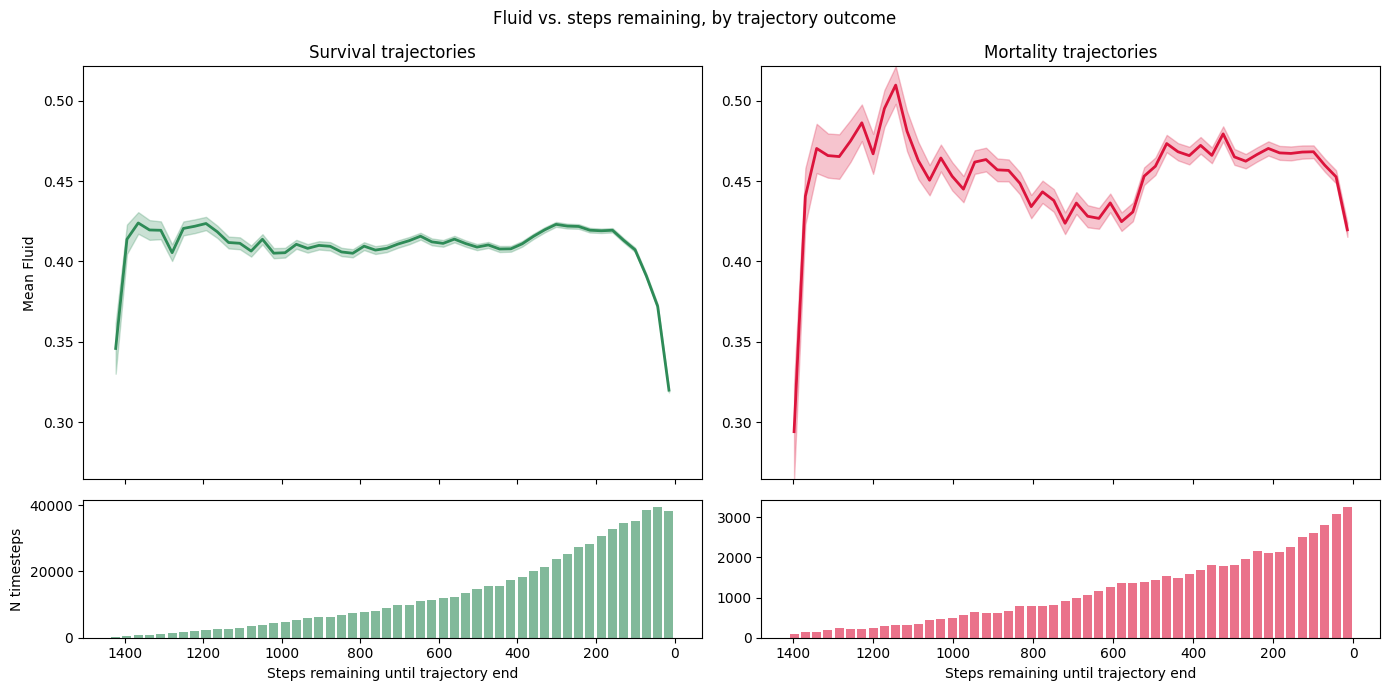

In [107]:
results_full_fluid = plot_dose_by_steps_remaining(intake, steps_to_go, mortality_all_steps, dose_name="Fluid")

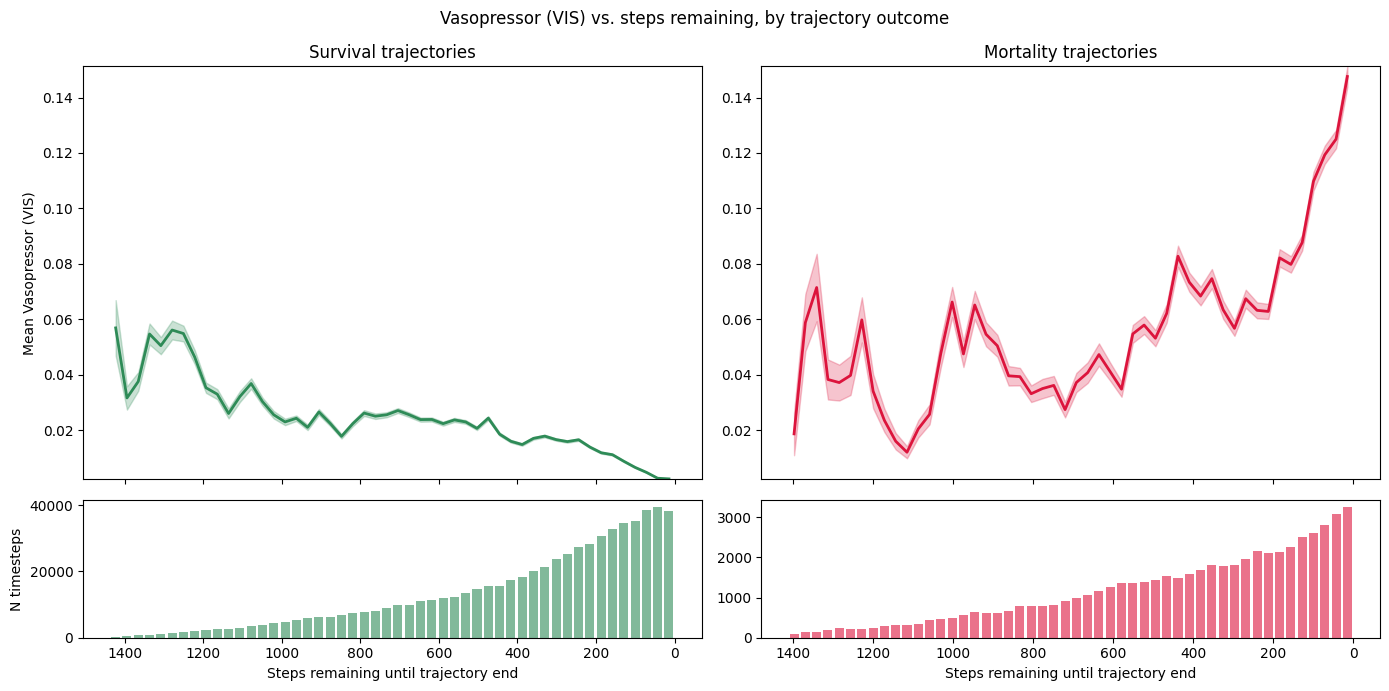

In [109]:
results_full_vis = plot_dose_by_steps_remaining(vis, steps_to_go, mortality_all_steps, dose_name="Vasopressor (VIS)")    

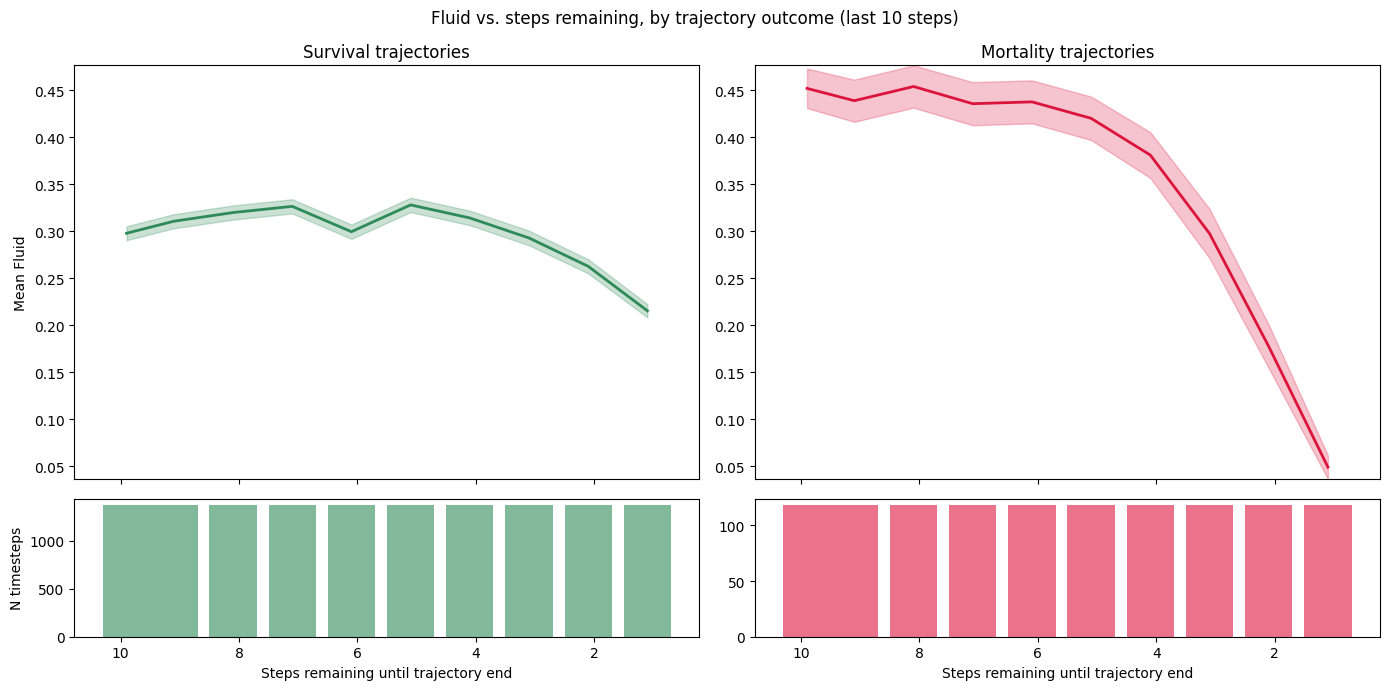

In [110]:
# usage — zoomed to last 10 steps, same n_bins now gives much finer resolution there
results_zoom = plot_dose_by_steps_remaining(intake, steps_to_go, mortality_all_steps,
                                             dose_name="Fluid", n_steps_to_go=10)